1 бизнес цель: сократить количество пропущенных случаев заболевания диабетом и уменьшить будущие расходы на лечение тяжёлых стадий диабета путем предсказания риска диабета на основе анализов.

Ориентиры: 
Recall ≥ 60%
F1-score ≥ 0.65
ROC-AUC ≥ 0.80

Модели:
Логистическая регрессия
Random Forest
Gradient Boosting

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import recall_score, f1_score, roc_auc_score
from sklearn.impute import IterativeImputer

df = pd.read_csv('diabetes.csv')

df_processed = df.copy()

cols_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_processed[cols_with_zero] = df_processed[cols_with_zero].replace(0, np.nan)

X = df_processed[["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", 
                  "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]]
y = df_processed["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

imputer = IterativeImputer(random_state=42, max_iter=10)
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

numeric_features = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ])

param_grids = {
    "Логистическая регрессия": {
        'clf__C': [0.01, 0.1, 1, 10],
        'clf__penalty': ['l1', 'l2'],
        'clf__solver': ['liblinear'],
        'clf__max_iter': [200, 500]
    },
    "Random Forest": {
        'clf__n_estimators': [100, 200],
        'clf__max_depth': [10, 20, None],
        'clf__min_samples_split': [2, 5],
        'clf__min_samples_leaf': [1, 2],
        'clf__max_features': ['sqrt', 'log2']
    },
    "Gradient Boosting": {
        'clf__n_estimators': [100, 200],
        'clf__learning_rate': [0.01, 0.1],
        'clf__max_depth': [3, 5],
        'clf__min_samples_split': [2, 5],
    }
}

pipelines = {
    "Логистическая регрессия": Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42))
    ]),
    "Random Forest": Pipeline([
        ('preprocessor', preprocessor),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ('preprocessor', preprocessor),
        ('clf', GradientBoostingClassifier(random_state=42))
    ])
}

best_models = {}
results = []


for name, pipeline in pipelines.items():
    print(f"\nМодель: {name}")
    
    if name == "Логистическая регрессия":
        search = GridSearchCV(
            pipeline,
            param_grids[name],
            cv=3, 
            scoring='roc_auc',
            n_jobs=-1,
            verbose=0
        )
    else:
        search = RandomizedSearchCV(
            pipeline,
            param_grids[name],
            n_iter=5,
            cv=3,
            scoring='roc_auc',
            n_jobs=-1,
            random_state=42,
            verbose=0
        )
    
    search.fit(X_train_imputed, y_train)
    
    best_models[name] = search.best_estimator_
    
    y_pred = search.predict(X_test_imputed)
    y_proba = search.predict_proba(X_test_imputed)[:, 1]
    
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    results.append({
        'Модель': name,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc,
        'Лучшие параметры': search.best_params_
    })
    
    print(f"Лучшие параметры: {search.best_params_}")
    print(f"Лучший ROC-AUC (кросс-валидация): {search.best_score_:.3f}")
    print(f"Recall на тесте: {recall:.3f}")
    print(f"F1-score на тесте: {f1:.3f}")
    print(f"ROC-AUC на тесте: {roc_auc:.3f}")



Модель: Логистическая регрессия
Лучшие параметры: {'clf__C': 0.1, 'clf__max_iter': 200, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Лучший ROC-AUC (кросс-валидация): 0.843
Recall на тесте: 0.704
F1-score на тесте: 0.633
ROC-AUC на тесте: 0.811

Модель: Random Forest
Лучшие параметры: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': None}
Лучший ROC-AUC (кросс-валидация): 0.826
Recall на тесте: 0.593
F1-score на тесте: 0.604
ROC-AUC на тесте: 0.823

Модель: Gradient Boosting
Лучшие параметры: {'clf__n_estimators': 200, 'clf__min_samples_split': 2, 'clf__max_depth': 3, 'clf__learning_rate': 0.01}
Лучший ROC-AUC (кросс-валидация): 0.825
Recall на тесте: 0.537
F1-score на тесте: 0.592
ROC-AUC на тесте: 0.807


Вывод: лучшая метрика - ROC-AUC, так как ROC-AUC устойчив к дисбалансу, а в задаче диагностики диабета обычно есть дисбаланс классов (здоровых больше, чем больных).
=> модель Random Forest лучше, так как у нее самый высокий ROC-AUC на тесте

2 бизнес цель: снизить количество пропущенных случаев преддиабета за счёт автоматической оценки глюкозы на основе легко собираемых показателей.

Ориентиры:
MAE ≤ 15-20 µU/mL
RMSE ≤ 20–25 µU/mL
R² ≥ 0.40–0.45

Модели:
Линейная регрессия
Decision Tree Regressor - Регрессия на основе деревьев решений
Gradient Boosting

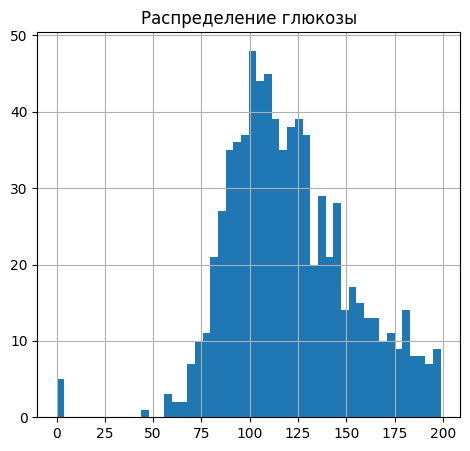


Значения равные 0:
Pregnancies: 111 нулей (14.5%)
Glucose: 5 нулей (0.7%)
BloodPressure: 35 нулей (4.6%)
SkinThickness: 227 нулей (29.6%)
Insulin: 374 нулей (48.7%)
BMI: 11 нулей (1.4%)
Outcome: 500 нулей (65.1%)


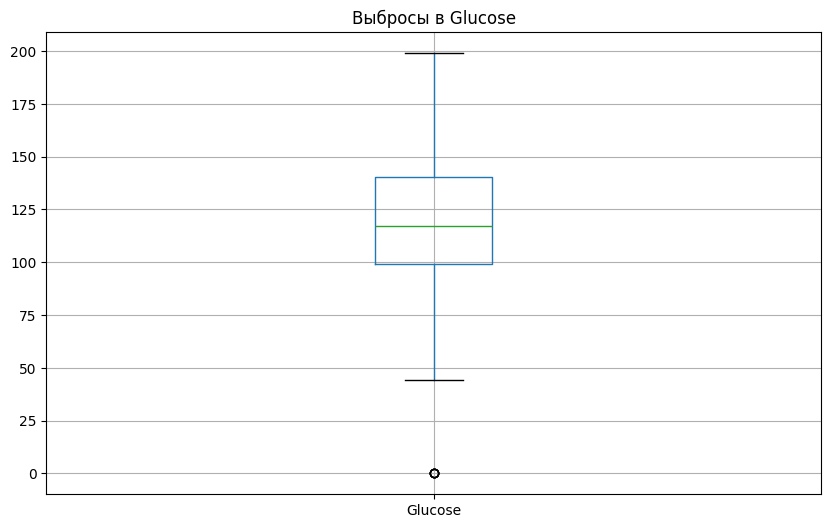

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv('diabetes.csv')


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
df['Glucose'].hist(bins=50)
plt.title('Распределение глюкозы')
plt.show()

print(f"\nЗначения равные 0:")
for col in df.columns:
    zero_count = (df[col] == 0).sum()
    if zero_count > 0:
        print(f"{col}: {zero_count} нулей ({zero_count/len(df)*100:.1f}%)")


plt.figure(figsize=(10, 6))
df.boxplot(column=['Glucose'])
plt.title('Выбросы в Glucose')
plt.show()

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import KNNImputer
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('diabetes.csv')

cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

imputer = KNNImputer(n_neighbors=5)
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

y = df_imputed["Glucose"]
X = df_imputed.drop('Glucose', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grids = {
    "Линейная регрессия": {
        'reg__fit_intercept': [True, False],
        'reg__positive': [False] 
    },
    "Random Forest": {
        'reg__n_estimators': [50, 100, 200, 300],
        'reg__max_depth': [None, 10, 20, 30, 40],
        'reg__min_samples_split': [2, 5, 10],
        'reg__min_samples_leaf': [1, 2, 4],
        'reg__max_features': ['sqrt', 'log2', None],
        'reg__bootstrap': [True, False]
    },
    "Gradient Boosting": {
        'reg__n_estimators': [50, 100, 200],
        'reg__learning_rate': [0.001, 0.01, 0.05, 0.1, 0.2],
        'reg__max_depth': [3, 5, 7, 9],
        'reg__min_samples_split': [2, 5, 10],
        'reg__min_samples_leaf': [1, 2, 4],
        'reg__subsample': [0.8, 0.9, 1.0],
        'reg__loss': ['squared_error', 'absolute_error', 'huber', 'quantile']
    }
}

pipelines = {
    "Линейная регрессия": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("reg", RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("reg", GradientBoostingRegressor(random_state=42))
    ])
}

results = []
best_models = {}

for name, pipeline in pipelines.items():
    print(f"\nМодель: {name}")
    
    if name in ["Линейная регрессия"]:
        search = GridSearchCV(
            pipeline,
            param_grids[name],
            cv=5,
            scoring='r2',
            n_jobs=-1,
            verbose=0
        )
    else:
        search = RandomizedSearchCV(
            pipeline,
            param_grids[name],
            n_iter=20,
            cv=3,
            scoring='r2',
            n_jobs=-1,
            random_state=42,
            verbose=0
        )
    
    search.fit(X_train, y_train)
    
    y_pred = search.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Модель': name,
        'MAE': mae,
        'RMSE': rmse,
        'R²': r2,
        'Лучшие параметры': search.best_params_
    })
    
    print(f"Лучшие параметры: {search.best_params_}")
    print(f"Лучший R² (кросс-валидация): {search.best_score_:.3f}")
    print(f"MAE на тесте: {mae:.2f}")
    print(f"RMSE на тесте: {rmse:.2f}")
    print(f"R² на тесте: {r2:.3f}")




Модель: Линейная регрессия
Лучшие параметры: {'reg__fit_intercept': True, 'reg__positive': False}
Лучший R² (кросс-валидация): 0.469
MAE на тесте: 17.62
RMSE на тесте: 21.85
R² на тесте: 0.526

Модель: Random Forest
Лучшие параметры: {'reg__n_estimators': 100, 'reg__min_samples_split': 5, 'reg__min_samples_leaf': 1, 'reg__max_features': 'log2', 'reg__max_depth': 30, 'reg__bootstrap': True}
Лучший R² (кросс-валидация): 0.503
MAE на тесте: 16.19
RMSE на тесте: 20.53
R² на тесте: 0.581

Модель: Gradient Boosting
Лучшие параметры: {'reg__subsample': 0.9, 'reg__n_estimators': 200, 'reg__min_samples_split': 10, 'reg__min_samples_leaf': 2, 'reg__max_depth': 7, 'reg__loss': 'absolute_error', 'reg__learning_rate': 0.1}
Лучший R² (кросс-валидация): 0.475
MAE на тесте: 16.42
RMSE на тесте: 21.16
R² на тесте: 0.555


Вывод: выбор лучшей метрики R², потому что показывает долю дисперсии целевой переменной, объясненную моделью, и В отличие от MAE и RMSE, R² не зависит от масштаба целевой переменной.
Лучшая модель - Random Forest, так как у нее самый высокий R².